# Fashion products: exploratory data analysis

* Imports and load data

In [ ]:
from pathlib import Path
from collections import Counter
from wordcloud import WordCloud
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
import sys

data_file = Path("..") / "data" / "processed_fashion_products.json" 
df = pd.read_json(data_file)
print(f"Loaded {len(df):,} products")

Loaded 28,080 products


* Dataset overview

This summarizes the dataset and checks its basic structure.

In [34]:
df.info()
df.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28080 entries, 0 to 28079
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   actual_price           28080 non-null  object 
 1   average_rating         28080 non-null  object 
 2   brand                  28080 non-null  object 
 3   category               28080 non-null  object 
 4   description            28080 non-null  object 
 5   discount               28080 non-null  object 
 6   out_of_stock           28080 non-null  bool   
 7   pid                    28080 non-null  object 
 8   product_details        28080 non-null  object 
 9   seller                 28080 non-null  object 
 10  selling_price          28080 non-null  object 
 11  sub_category           28080 non-null  object 
 12  title                  28080 non-null  object 
 13  url                    28080 non-null  object 
 14  processed_title        28080 non-null  object 
 15  pr

,actual_price,average_rating,brand,category,description,discount,out_of_stock,pid,product_details,seller,...,title,url,processed_title,processed_description,is_available,selling_price_value,actual_price_value,discount_percent,average_rating_value,processed_metadata
0,"2,999",3.9,York,Clothing and Accessories,Yorker trackpants made from 100% rich combed c...,69% off,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,...,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",True,921.0,2999.0,69.0,3.9,"[york, bottomwear, elast, side, pocket, cotton..."
1,"1,499",3.9,York,Clothing and Accessories,Yorker trackpants made from 100% rich combed c...,66% off,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,...,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...,"[solid, men, blue, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",True,499.0,1499.0,66.0,3.9,"[york, bottomwear, drawstr, elast, side, pocke..."
2,"2,999",3.9,York,Clothing and Accessories,Yorker trackpants made from 100% rich combed c...,68% off,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,...,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...,"[solid, men, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",True,931.0,2999.0,68.0,3.9,"[york, bottomwear, elast, side, pocket, cotton..."
3,"2,999",3.9,York,Clothing and Accessories,Yorker trackpants made from 100% rich combed c...,69% off,False,TKPFCZ9ESZZ7YWEF,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,...,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",True,911.0,2999.0,69.0,3.9,"[york, bottomwear, elast, side, pocket, cotton..."
4,"2,999",3.9,York,Clothing and Accessories,Yorker trackpants made from 100% rich combed c...,68% off,False,TKPFCZ9EVXKBSUD7,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,...,"Solid Women Brown, Grey Track Pants",https://www.flipkart.com/yorker-solid-men-brow...,"[solid, women, brown, grey, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",True,943.0,2999.0,68.0,3.9,"[york, bottomwear, drawstr, elast, side, pocke..."


* Text fields and vocabulary

These plots show how much text is available and which terms are common.

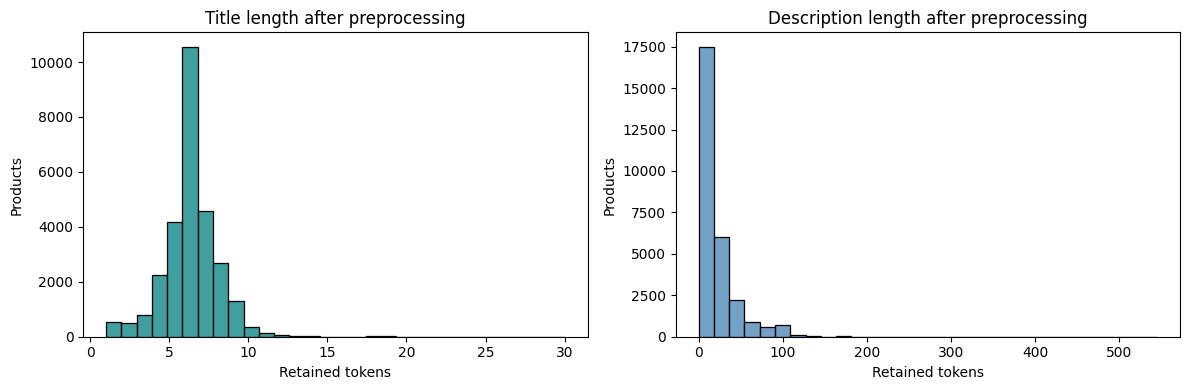

,count,mean,std,min,25%,50%,75%,max
title_token_count,28080.0,6.08,1.87,1.0,5.0,6.0,7.0,30.0
description_token_count,28080.0,18.70,26.54,0.0,0.0,9.0,29.0,545.0


In [20]:
def token_list(value):
    return value if isinstance(value, list) else []

df["title_token_count"] = df["processed_title"].map(lambda x: len(token_list(x)))
df["description_token_count"] = df["processed_description"].map(lambda x: len(token_list(x)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["title_token_count"], bins=30, ax=axes[0], color="teal")
axes[0].set(title="Title length after preprocessing", xlabel="Retained tokens", ylabel="Products")
sns.histplot(df["description_token_count"], bins=30, ax=axes[1], color="steelblue")
axes[1].set(title="Description length after preprocessing", xlabel="Retained tokens", ylabel="Products")
plt.tight_layout()
plt.show()

display(df[["title_token_count", "description_token_count"]].describe().T.round(2))

Total retained title + description tokens: 695,782
Vocabulary size (unique stemmed tokens): 4,875


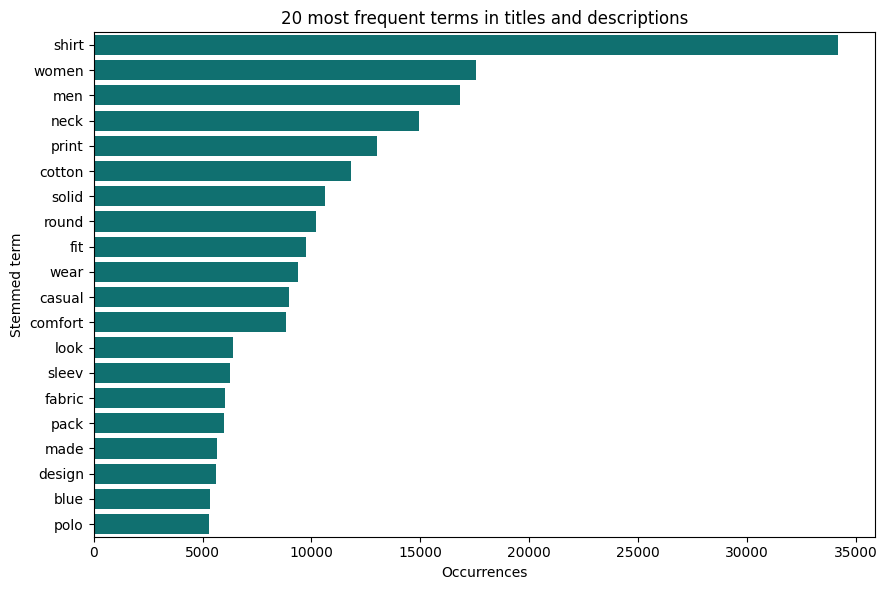

In [21]:
text_tokens = [token for column in ["processed_title", "processed_description"]
               for value in df[column] for token in token_list(value)]
term_counts = Counter(text_tokens)
vocabulary = set(text_tokens)

print(f"Total retained title + description tokens: {len(text_tokens):,}")
print(f"Vocabulary size (unique stemmed tokens): {len(vocabulary):,}")

top_terms = pd.DataFrame(term_counts.most_common(20), columns=["Stemmed term", "Occurrences"])
plt.figure(figsize=(9, 6))
sns.barplot(data=top_terms, x="Occurrences", y="Stemmed term", color="teal")
plt.title("20 most frequent terms in titles and descriptions")
plt.tight_layout()
plt.show()

* Top Sub-categories and brands

These counts show which product types and brands appear most often.

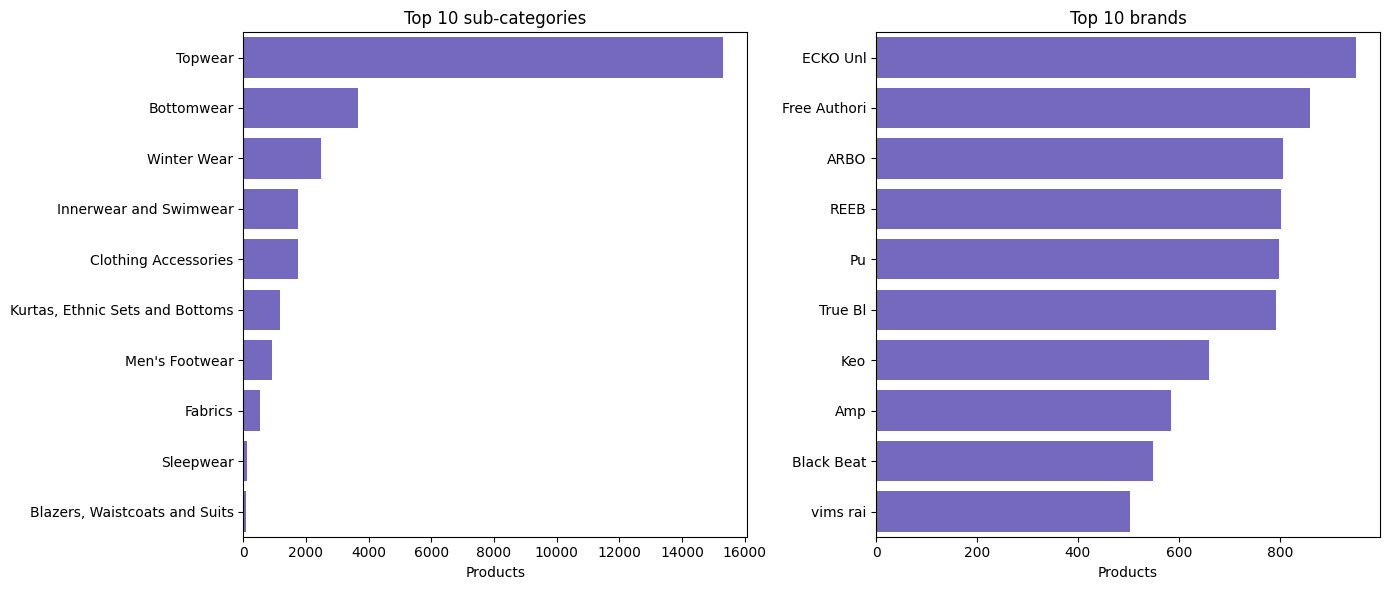

In [5]:
def top_counts(column, n=10):
    return df[column].dropna().astype(str).str.strip().replace("", np.nan).dropna().value_counts().head(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, column, title in [
    (axes[0], "sub_category", "Top 10 sub-categories"),
    (axes[1], "brand", "Top 10 brands"),
]:
    counts = top_counts(column)
    sns.barplot(x=counts.values, y=counts.index, ax=ax, color="slateblue")
    ax.set(title=title, xlabel="Products", ylabel="")
plt.tight_layout()
plt.show()

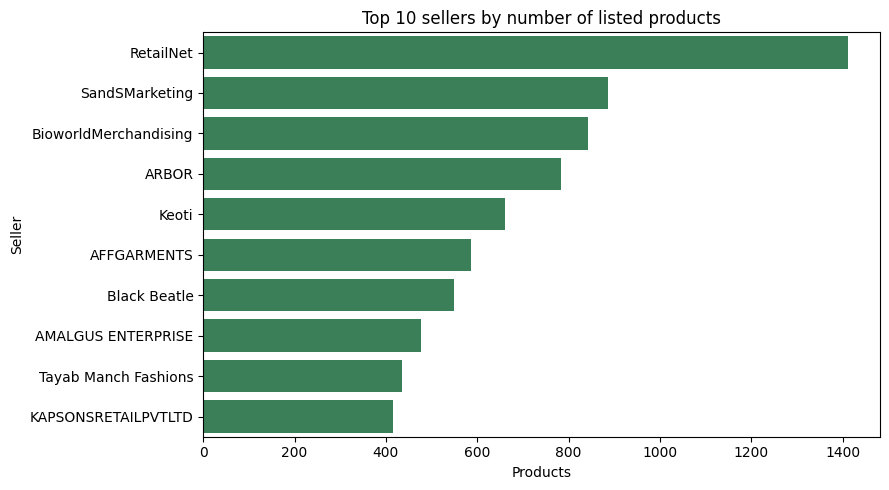

In [6]:
seller_counts = top_counts("seller", n=10)
plt.figure(figsize=(9, 5))
sns.barplot(x=seller_counts.values, y=seller_counts.index, color="seagreen")
plt.title("Top 10 sellers by number of listed products")
plt.xlabel("Products")
plt.ylabel("Seller")
plt.tight_layout()
plt.show()

* Commercial attributes

These plots summarize availability, prices, discounts, and ratings.

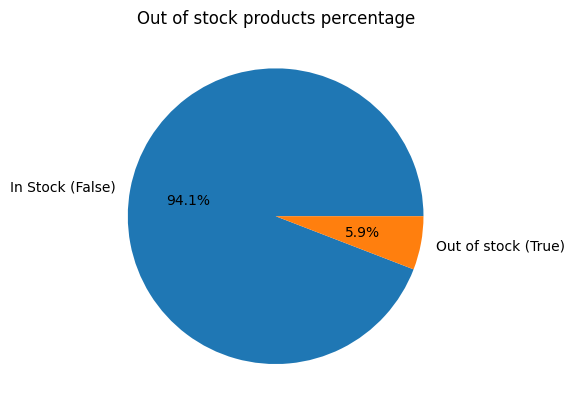

In [ ]:
stock_counts = df['is_available'].value_counts()

plt.pie(stock_counts, labels=['In Stock (False)', 'Out of stock (True)'], 
        autopct='%1.1f%%')
plt.title('Out of stock products percentage', fontsize=12)
plt.show()

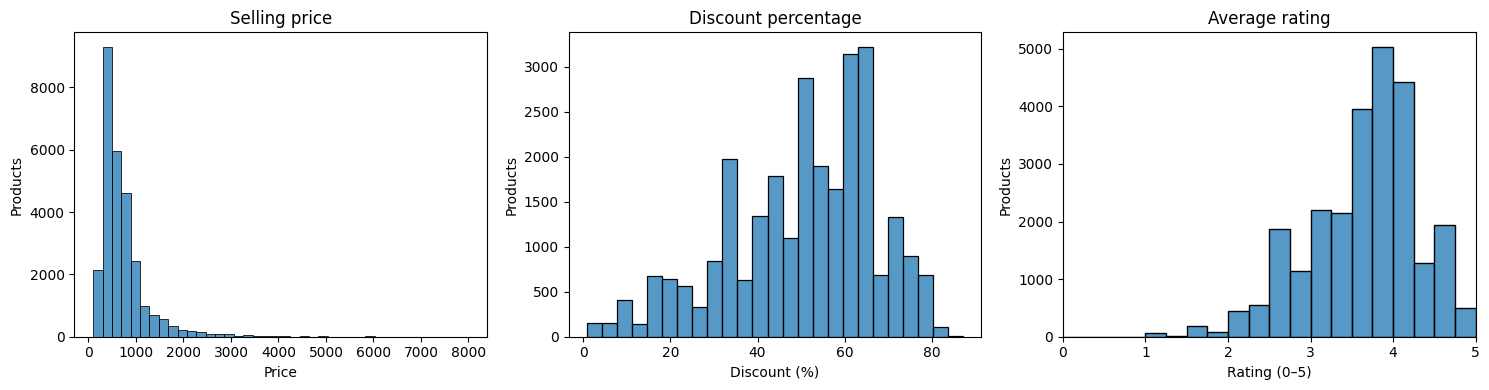

,selling_price_value,discount_percent,average_rating_value
count,28078.000000,27225.000000,25819.000000
mean,705.635088,50.256896,3.627724
std,549.681489,16.887287,0.663429
min,99.000000,1.000000,1.000000
25%,390.000000,40.000000,3.200000
50%,545.000000,53.000000,3.800000
75%,820.000000,63.000000,4.100000
max,7999.000000,87.000000,5.000000


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

prices = df["selling_price_value"].dropna()

sns.histplot(prices, bins=40, ax=axes[0])
axes[0].set(title="Selling price", xlabel="Price", ylabel="Products")

discounts = df["discount_percent"].dropna()
sns.histplot(discounts, bins=25, ax=axes[1])
axes[1].set(title="Discount percentage", xlabel="Discount (%)", ylabel="Products")

ratings = df["average_rating_value"].dropna()
sns.histplot(ratings, bins=np.arange(0, 5.25, 0.25), ax=axes[2])
axes[2].set(title="Average rating", xlabel="Rating (0–5)", ylabel="Products", xlim=(0, 5))

plt.tight_layout()
plt.show()
display(df[["selling_price_value", "discount_percent", "average_rating_value"]].describe())

* Word cloud

The word cloud gives a visual overview of common description terms.

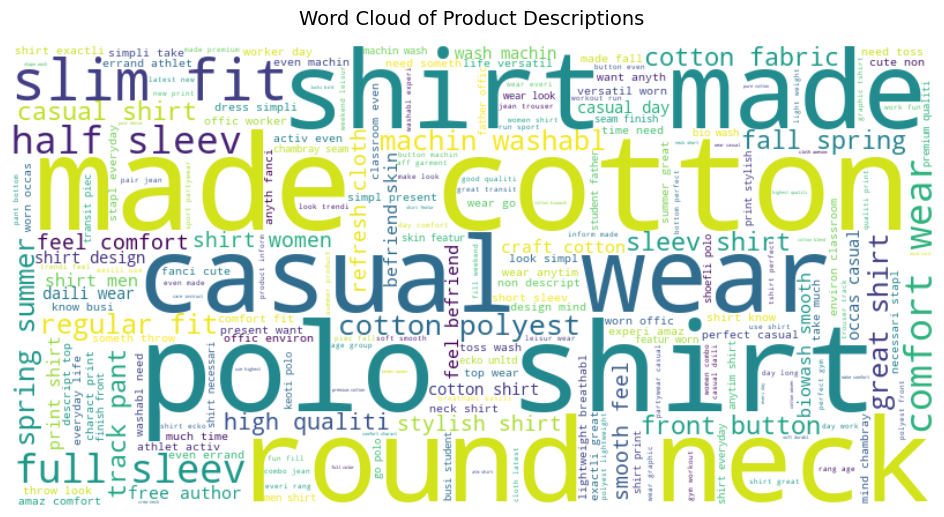

In [27]:
all_text = " ".join([
    token for sublist in df['processed_description'].dropna() 
    if isinstance(sublist, list) 
    for token in sublist
])

wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Product Descriptions', fontsize=14, pad=15)
plt.show()

* Exploratory named-entity recognition

NER finds possible names in a sample; its results may not always be accurate.

In [ ]:
#only once
!{sys.executable} -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---- ----------------------------------- 1.6/12.8 MB 7.0 MB/s eta 0:00:02
     --------- ------------------------------ 3.1/12.8 MB 7.7 MB/s eta 0:00:02
     -------------- ------------------------- 4.7/12.8 MB 7.5 MB/s eta 0:00:02
     -------------------- ------------------- 6.6/12.8 MB 7.7 MB/s eta 0:00:01
     ------------------------- -------------- 8.1/12.8 MB 7.9 MB/s eta 0:00:01
     ------------------------------- -------- 10.0/12.8 MB 8.0 MB/s eta 0:00:01
     ------------------------------------ --- 11.5/12.8 MB 8.0 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 7.6 MB/s  0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\paudu\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


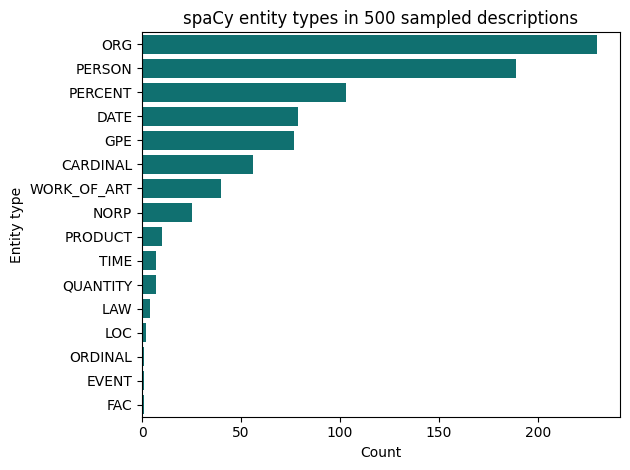

Most frequent entity examples (surface form, label):


,Entity,Type,Count
0,100%,PERCENT,47
1,Cotton,GPE,25
2,60%,PERCENT,25
3,40%,PERCENT,23
4,Some days,DATE,13
5,kurta,GPE,12
6,Jeans,NORP,10
7,daily,DATE,10
8,Arbour,PERSON,8
9,India,GPE,7


In [ ]:
nlp = spacy.load("en_core_web_sm")
descriptions = df["description"].dropna().astype(str)
ner_sample = descriptions.sample(n=min(500, len(descriptions)), random_state=42)
disabled = [name for name in ["parser", "lemmatizer", "textcat"] if name in nlp.pipe_names]
docs = nlp.pipe(ner_sample, batch_size=32, disable=disabled)
entity_types = Counter(entity.label_ for doc in docs for entity in doc.ents)
entity_table = pd.DataFrame(entity_types.most_common(), columns=["Entity type", "Count"])
if entity_table.empty:
    print("No entities were detected in the sample.")
else:
    sns.barplot(data=entity_table, x="Count", y="Entity type", color="teal")
    plt.title(f"spaCy entity types in {len(ner_sample)} sampled descriptions")
    plt.tight_layout()
    plt.show()
    print("Most frequent entity examples (surface form, label):")
    entity_examples = Counter( (entity.text.strip(), entity.label_)
    for doc in nlp.pipe(ner_sample, batch_size=32, disable=disabled)
        for entity in doc.ents if entity.text.strip())
    display(pd.DataFrame([(text, label, count) for (text, label), count in entity_examples.most_common(15)],
                columns=["Entity", "Type", "Count"]))